# Loading Libraries
> **Corrected version.** The original is kept as `Text_Preprocessing_original.ipynb`. The preprocessing cells are unchanged; the problems found in them are explained in the new section 'Corrections' at the end (the 99.45 % accuracy is mostly caused by emoticons that define the labels).

In [1]:
import nltk                                  # Python library for NLP
from nltk.corpus import twitter_samples      # sample Twitter dataset from NLTK
import matplotlib.pyplot as plt              
import numpy as np                           
import random

In [2]:
# !pip install nltk

# Loading Dataset

In [3]:
# downloads sample twitter dataset. uncomment the line below if running on a local machine.
nltk.download('twitter_samples')

# select the set of positive and negative tweets
all_positive_tweets = twitter_samples.strings('positive_tweets.json')
all_negative_tweets = twitter_samples.strings('negative_tweets.json')

print('Number of positive tweets: ', len(all_positive_tweets))
print('Number of negative tweets: ', len(all_negative_tweets))

print('\nThe type of all_positive_tweets is: ', type(all_positive_tweets))
print('The type of a tweet entry is: ', type(all_negative_tweets[0]))

[nltk_data] Error loading twitter_samples: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.


Number of positive tweets:  5000
Number of negative tweets:  5000

The type of all_positive_tweets is:  <class 'list'>
The type of a tweet entry is:  <class 'str'>


In [4]:
# print positive in greeen
print('\033[92m' + all_positive_tweets[random.randint(0,5000)])

# print negative in red
print('\033[91m' + all_negative_tweets[random.randint(0,5000)])

Will you be my happy ending? @IanPrasetya insyaAllah :)
@Mars_Sum41 noooo :( goodbye fun driving


In [5]:
# Our selected sample. Complex enough to exemplify each step
tweet = all_positive_tweets[2277]
print(tweet)

My beautiful sunflowers on a sunny Friday morning off :) #sunflowers #favourites #happy #Friday off… https://t.co/3tfYom0N1i


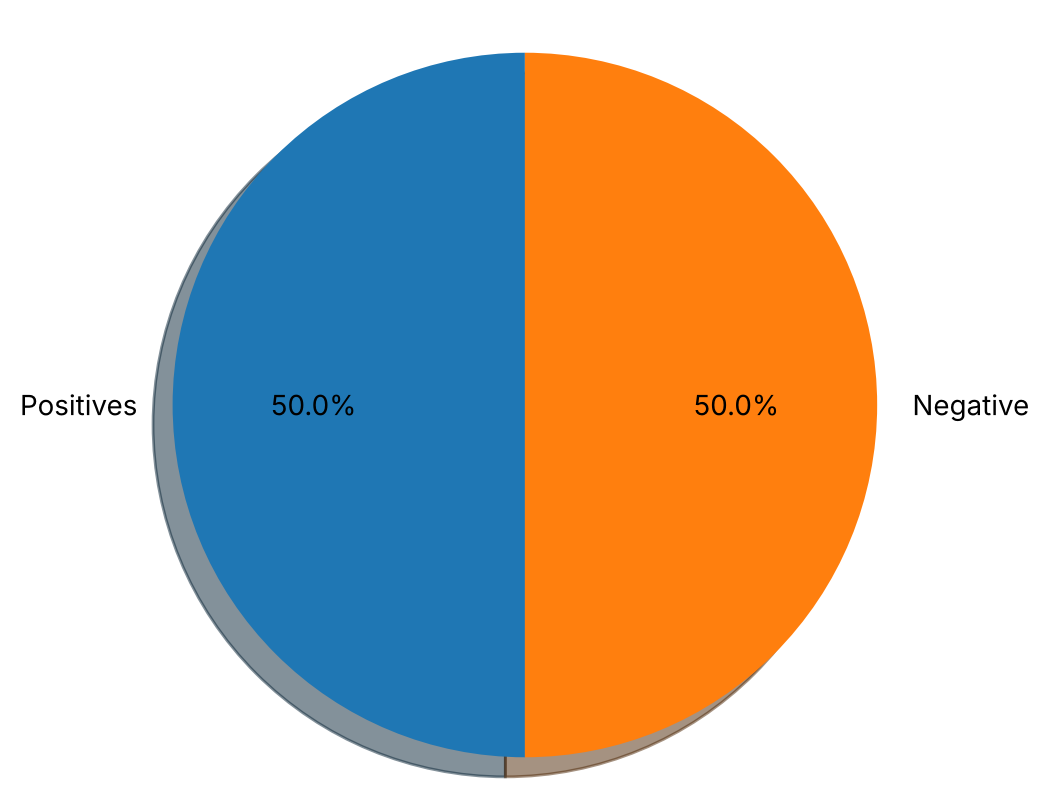

In [6]:
# Declare a figure with a custom size
fig = plt.figure(figsize=(5, 5))

# labels for the two classes
labels = 'Positives', 'Negative'

# Sizes for each slide
sizes = [len(all_positive_tweets), len(all_negative_tweets)]

# Declare pie chart, where the slices will be ordered and plotted counter-clockwise:
plt.pie(sizes, labels=labels, autopct='%1.1f%%',
        shadow=True, startangle=90)

# Equal aspect ratio ensures that pie is drawn as a circle.
plt.axis('equal')

# Display the chart
plt.show()


# Text Cleaning and Preprocessing

In [7]:
import re                                  # library for regular expression operations
import string                              # for string operations

from nltk.corpus import stopwords          # module for stop words that come with NLTK
from nltk.stem import PorterStemmer        # module for stemming
from nltk.tokenize import TweetTokenizer   # module for tokenizing strings

In [8]:
print('\033[92m' + tweet)
print('\033[94m')

# remove old style retweet text "RT"
tweet2 = re.sub(r'^RT[\s]+', '', tweet)

# remove hyperlinks
tweet2 = re.sub(r'https?:\/\/.*[\r\n]*', '', tweet2)

# remove hashtags
# only removing the hash # sign from the word
tweet2 = re.sub(r'#', '', tweet2)
tweet2 = re.sub(r'…', '', tweet2)

print(tweet2)

My beautiful sunflowers on a sunny Friday morning off :) #sunflowers #favourites #happy #Friday off… https://t.co/3tfYom0N1i

My beautiful sunflowers on a sunny Friday morning off :) sunflowers favourites happy Friday off 


In [9]:
print()
print('\033[92m' + tweet2)
print('\033[94m')

# instantiate tokenizer class
tokenizer = TweetTokenizer(preserve_case=False, strip_handles=True,
                               reduce_len=True)

# tokenize tweets
tweet_tokens = tokenizer.tokenize(tweet2)

print()
print('Tokenized string:')
print(tweet_tokens)


My beautiful sunflowers on a sunny Friday morning off :) sunflowers favourites happy Friday off 


Tokenized string:
['my', 'beautiful', 'sunflowers', 'on', 'a', 'sunny', 'friday', 'morning', 'off', ':)', 'sunflowers', 'favourites', 'happy', 'friday', 'off']


In [10]:
## making text cleaning function
def clean_tweet(tweet):
    # remove old style retweet text "RT"
    clean_tweet = re.sub(r'^RT[\s]+', '', tweet)
    # remove hyperlinks
    clean_tweet = re.sub(r'https?:\/\/.*[\r\n]*', '', clean_tweet)
    # remove hashtags
    # only removing the hash # sign from the word
    clean_tweet = re.sub(r'#', '', clean_tweet)
    clean_tweet = re.sub(r'…', '', clean_tweet)
    # remove mentions
    clean_tweet = re.sub(r'@\w+', '', clean_tweet)
    return clean_tweet

all_positive_cleaned = [clean_tweet(tweet) for tweet in all_positive_tweets]
all_negative_cleaned = [clean_tweet(tweet) for tweet in all_negative_tweets]  

In [11]:
all_positive_tweets[227]

'@coffeebreak22 @LauRenArren @drparkave @JWKanyuira1969 @dheracing @RhoaChri @BarbaraBathurst @1cryingeye @willisteam :) ☕☕☕ Thank you Rita!'

In [12]:
all_positive_cleaned[227]

'         :) ☕☕☕ Thank you Rita!'

In [13]:
all_negative_tweets[227]

'@energybiebers Sigh... :('

In [14]:
all_negative_cleaned[227]

' Sigh... :('

In [15]:
# download the stopwords from NLTK
nltk.download('stopwords')

[nltk_data] Error loading stopwords: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.


False

In [16]:
#Import the english stop words list from NLTK
stopwords_english = stopwords.words('english')

print('Stop words\n')
print(stopwords_english)

print('\nPunctuation\n')
print(string.punctuation)

Stop words

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "s

In [17]:
print(len(stopwords_english))

198


In [18]:
print()
print('\033[92m')
print(tweet_tokens)
print('\033[94m')

tweets_clean = []

for word in tweet_tokens: # Go through every word in your tokens list
    if (word not in stopwords_english and  # remove stopwords
        word not in string.punctuation):  # remove punctuation
        tweets_clean.append(word)

print('removed stop words and punctuation:')
print(tweets_clean)



['my', 'beautiful', 'sunflowers', 'on', 'a', 'sunny', 'friday', 'morning', 'off', ':)', 'sunflowers', 'favourites', 'happy', 'friday', 'off']

removed stop words and punctuation:
['beautiful', 'sunflowers', 'sunny', 'friday', 'morning', ':)', 'sunflowers', 'favourites', 'happy', 'friday']


In [19]:
# NOTE: `word not in string.punctuation` is a SUBSTRING test on one long string; it removes ')' but keeps ':)'
def remove_stopwords(tweet):
    ## tokenize tweet
    tweet_tokens = tokenizer.tokenize(tweet)
    tweets_clean = []
    for word in tweet_tokens:
        if (word not in stopwords_english and  # remove stopwords
            word not in string.punctuation):  # remove punctuation
            tweets_clean.append(word)
    return tweets_clean

fin_all_positives = [remove_stopwords(tweet) for tweet in all_positive_cleaned]
fin_all_negatives = [remove_stopwords(tweet) for tweet in all_negative_cleaned]

In [20]:
len(fin_all_positives)

5000

In [21]:
fin_all_positives[227]

[':)', '☕', '☕', '☕', 'thank', 'rita']

In [22]:
fin_all_negatives[227]

['sigh', '...', ':(']

In [23]:
print()
print('\033[92m')
print(tweets_clean)
print('\033[94m')

# Instantiate stemming class
stemmer = PorterStemmer()

# Create an empty list to store the stems
tweets_stem = []

for word in tweets_clean:
    stem_word = stemmer.stem(word)  # stemming word
    tweets_stem.append(stem_word)  # append to the list

print('stemmed words:')
print(tweets_stem)



['beautiful', 'sunflowers', 'sunny', 'friday', 'morning', ':)', 'sunflowers', 'favourites', 'happy', 'friday']

stemmed words:
['beauti', 'sunflow', 'sunni', 'friday', 'morn', ':)', 'sunflow', 'favourit', 'happi', 'friday']


In [24]:
import nltk
from nltk.stem import WordNetLemmatizer

print()
print('\033[92m')
print(tweets_clean)
print('\033[94m')

# Instantiate stemming class
lemmatizer = WordNetLemmatizer()

# Create an empty list to store the stems
tweets_lem = []

for word in tweets_clean:
    lem_word = lemmatizer.lemmatize(word)  # stemming word
    tweets_lem.append(lem_word)  # append to the list

print('Lemmitized words:')
print(tweets_lem)



['beautiful', 'sunflowers', 'sunny', 'friday', 'morning', ':)', 'sunflowers', 'favourites', 'happy', 'friday']



Lemmitized words:
['beautiful', 'sunflower', 'sunny', 'friday', 'morning', ':)', 'sunflower', 'favourite', 'happy', 'friday']


In [25]:
def remove_stopwords_fin(tweet, stem=False, lemmitize=False):
    
    ## tokenize tweet
    tweet_tokens = tokenizer.tokenize(tweet)
    tweets_clean = []
    for word in tweet_tokens:
        if stem:
            stemmer = PorterStemmer()
            word = stemmer.stem(word)
        if lemmitize:
            lemmatizer = WordNetLemmatizer()
            word = lemmatizer.lemmatize(word)
        if (word not in stopwords_english and  # remove stopwords
            word not in string.punctuation):  # remove punctuation
            tweets_clean.append(word)
    return tweets_clean

In [26]:
# NOTE: stem=False and lemmitize=False by default, so these lists are NOT stemmed (the name is misleading)
all_positive_stemmed = [remove_stopwords_fin(tweet) for tweet in all_positive_cleaned]
all_negative_stemmed = [remove_stopwords_fin(tweet) for tweet in all_negative_cleaned]

In [27]:
all_positive_stemmed[0]

['followfriday', 'top', 'engaged', 'members', 'community', 'week', ':)']

In [28]:
all_negative_stemmed[227]

['sigh', '...', ':(']

## **Encoding the text data**

In [29]:
# NOTE: the vocabulary is built from ALL tweets, before the split: build it from the training tweets only (see 'Corrections')
all_clean_tweets = all_positive_stemmed + all_negative_stemmed

### creating vocabulary set
vocab = set()
for tweet in all_clean_tweets:
    for word in tweet:
        vocab.add(word.lower())

len(vocab)

12335

In [30]:
### indexing vocabulary
word2index = {}
index2word = {}
for i, word in enumerate(vocab):
    word2index[word] = i
    index2word[i] = word

In [31]:
word2index

{'fellow': 0,
 'states': 1,
 'vocals': 2,
 'receptionist': 3,
 'mayor': 4,
 'chewing': 5,
 'identified': 6,
 'everyones': 7,
 'repost': 8,
 'nighter': 9,
 'aku': 10,
 'ear': 11,
 'lice': 12,
 'dough': 13,
 'alvadhaau': 14,
 '3.4': 15,
 "party's": 16,
 'cimbom': 17,
 'cs': 18,
 'yumu-youtuber': 19,
 'annabel': 20,
 '다쇼': 21,
 'wasted': 22,
 'migrant': 23,
 'outfwith': 24,
 "year's": 25,
 'lonely': 26,
 'smu': 27,
 'cali': 28,
 'half-remembered': 29,
 'monash': 30,
 'kardamena': 31,
 'jest': 32,
 'aja': 33,
 'tweeeps': 34,
 'everywhere': 35,
 'fansign': 36,
 'aready': 37,
 'nemesis': 38,
 'snobby': 39,
 'fifa': 40,
 'jk': 41,
 'beks': 42,
 'city': 43,
 'loses': 44,
 'flowers': 45,
 'nikeindonesia': 46,
 'himachal': 47,
 "panic's": 48,
 'joint': 49,
 'jackie': 50,
 'dress': 51,
 'crumble': 52,
 'recover': 53,
 'yr': 54,
 'please': 55,
 'gaming': 56,
 'messages': 57,
 '💟': 58,
 'incredible': 59,
 'kaha': 60,
 'sel': 61,
 'miller': 62,
 'customers': 63,
 'condemned': 64,
 'usage': 65,
 'tel

In [32]:
index2word

{0: 'fellow',
 1: 'states',
 2: 'vocals',
 3: 'receptionist',
 4: 'mayor',
 5: 'chewing',
 6: 'identified',
 7: 'everyones',
 8: 'repost',
 9: 'nighter',
 10: 'aku',
 11: 'ear',
 12: 'lice',
 13: 'dough',
 14: 'alvadhaau',
 15: '3.4',
 16: "party's",
 17: 'cimbom',
 18: 'cs',
 19: 'yumu-youtuber',
 20: 'annabel',
 21: '다쇼',
 22: 'wasted',
 23: 'migrant',
 24: 'outfwith',
 25: "year's",
 26: 'lonely',
 27: 'smu',
 28: 'cali',
 29: 'half-remembered',
 30: 'monash',
 31: 'kardamena',
 32: 'jest',
 33: 'aja',
 34: 'tweeeps',
 35: 'everywhere',
 36: 'fansign',
 37: 'aready',
 38: 'nemesis',
 39: 'snobby',
 40: 'fifa',
 41: 'jk',
 42: 'beks',
 43: 'city',
 44: 'loses',
 45: 'flowers',
 46: 'nikeindonesia',
 47: 'himachal',
 48: "panic's",
 49: 'joint',
 50: 'jackie',
 51: 'dress',
 52: 'crumble',
 53: 'recover',
 54: 'yr',
 55: 'please',
 56: 'gaming',
 57: 'messages',
 58: '💟',
 59: 'incredible',
 60: 'kaha',
 61: 'sel',
 62: 'miller',
 63: 'customers',
 64: 'condemned',
 65: 'usage',
 66: 

In [33]:
def one_hot_encode(tweet, word_to_index, vocab_size):
    encoding = np.zeros(vocab_size, dtype=int)
    for word in tweet:
        if word in word_to_index:  # Ignore words not in the vocabulary
            encoding[word_to_index[word]] = 1
    return encoding

In [34]:
enc_positives = [one_hot_encode(tweet, word2index, len(vocab)) for tweet in all_positive_stemmed]
enc_negatives = [one_hot_encode(tweet, word2index, len(vocab)) for tweet in all_negative_stemmed]

In [35]:
enc_positives[0]

array([0, 0, 0, ..., 0, 0, 0], shape=(12335,))

In [36]:
enc_negatives[0]

array([0, 0, 0, ..., 0, 0, 0], shape=(12335,))

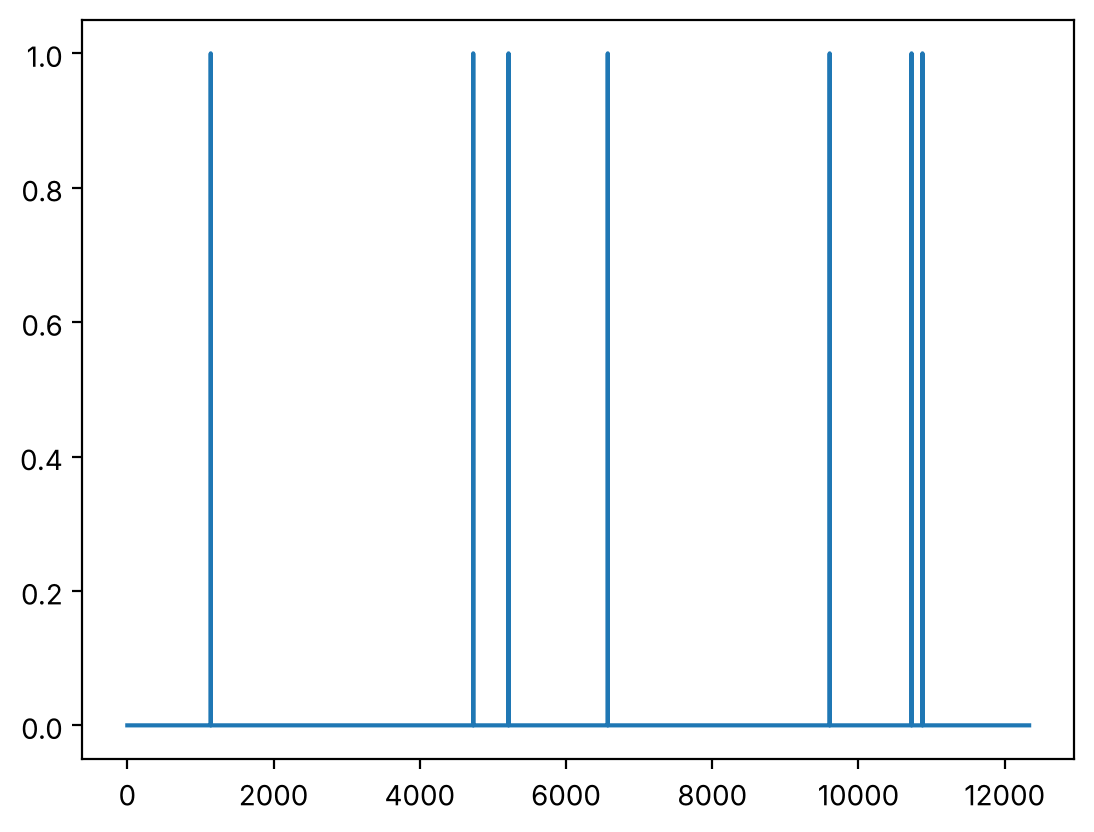

In [37]:
plt.plot(enc_positives[0])

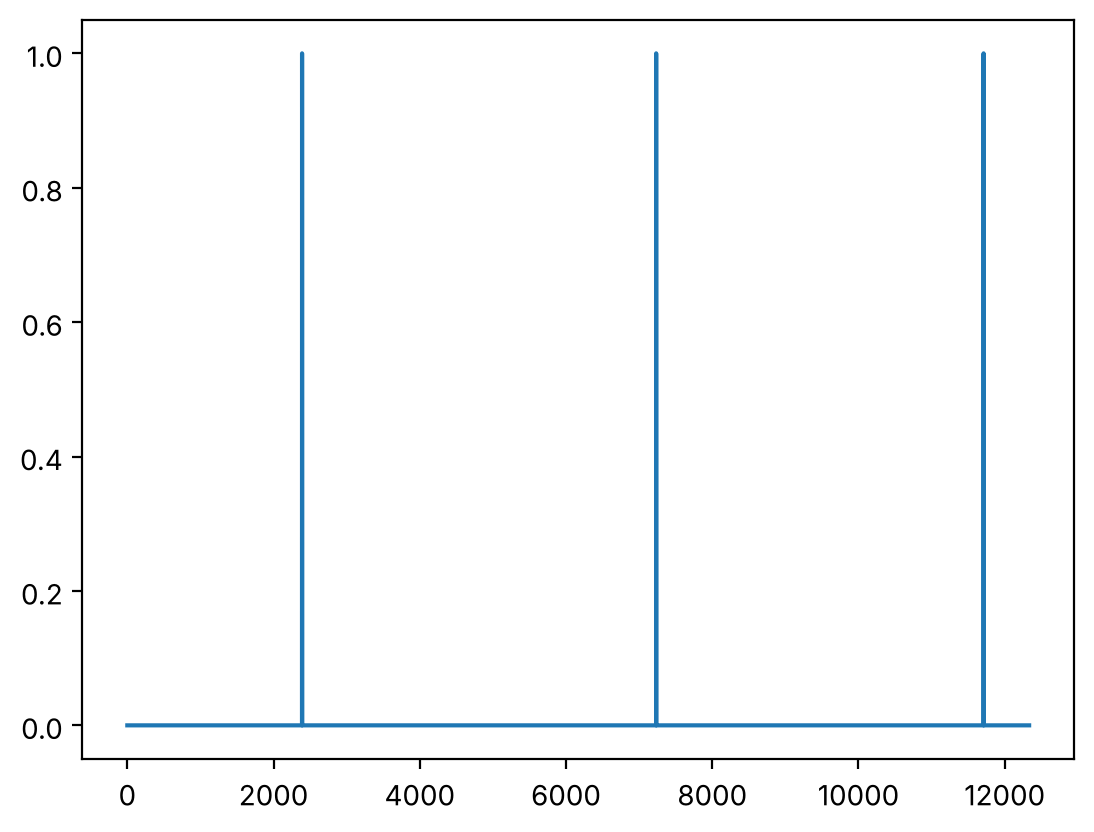

In [38]:
plt.plot(enc_negatives[227])

In [39]:
# Combine positive and negative encodings into one dataset
X = np.array(enc_positives + enc_negatives)  # Feature matrix
y = np.array([1] * len(enc_positives) + [0] * len(enc_negatives))  # Labels (1 = positive, 0 = negative)
X.shape, y.shape

((10000, 12335), (10000,))

In [40]:
y

array([1, 1, 1, ..., 0, 0, 0], shape=(10000,))

In [41]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(8000, 12335)
(2000, 12335)
(8000,)
(2000,)


In [42]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Step 4: Make predictions
y_pred = model.predict(X_test)

# Step 5: Evaluate the Model
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy of Logistic Regression model:", accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy of Logistic Regression model: 0.9945

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       988
           1       0.99      1.00      0.99      1012

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000



In [43]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
# from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression

# Step 3: Define the models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Support Vector Machine (SVM)": SVC(kernel='linear', probability=True),
    "Naive Bayes": MultinomialNB(),
    "K-Nearest Neighbors (KNN)": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
    # "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
}

# Step 4: Train and evaluate each model
results = {}
for model_name, model in models.items():
    print(f"\nTraining {model_name}...")
    model.fit(X_train, y_train)  # Train the model
    y_pred = model.predict(X_test)  # Predict on test set
    accuracy = accuracy_score(y_test, y_pred)  # Calculate accuracy
    results[model_name] = accuracy  # Store accuracy for comparison
    print(f"{model_name} Accuracy: {accuracy:.4f}")
    print(classification_report(y_test, y_pred))

# Step 5: Display model performance comparison
print("\nModel Performance Comparison:")
for model_name, accuracy in results.items():
    print(f"{model_name}: {accuracy:.4f}")



Training Logistic Regression...


Logistic Regression Accuracy: 0.9945
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       988
           1       0.99      1.00      0.99      1012

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000


Training Support Vector Machine (SVM)...


/usr/local/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Support Vector Machine (SVM) Accuracy: 0.9945
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       988
           1       0.99      1.00      0.99      1012

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000


Training Naive Bayes...


Naive Bayes Accuracy: 0.9685
              precision    recall  f1-score   support

           0       0.94      0.99      0.97       988
           1       0.99      0.94      0.97      1012

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000


Training K-Nearest Neighbors (KNN)...


K-Nearest Neighbors (KNN) Accuracy: 0.9885
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       988
           1       0.98      0.99      0.99      1012

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000


Training Decision Tree...


Decision Tree Accuracy: 0.9900
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       988
           1       0.99      0.99      0.99      1012

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000


Training Random Forest...


Random Forest Accuracy: 0.9930
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       988
           1       0.99      0.99      0.99      1012

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000


Model Performance Comparison:
Logistic Regression: 0.9945
Support Vector Machine (SVM): 0.9945
Naive Bayes: 0.9685
K-Nearest Neighbors (KNN): 0.9885
Decision Tree: 0.9900
Random Forest: 0.9930


# Corrections

Three problems in the pipeline above, and a measurement of the first one.

1. **Label leakage through emoticons.** The NLTK `twitter_samples` corpus was collected by searching for `:)` (positive) and `:(` (negative). The tokenizer keeps the emoticon as a token (`':)' in string.punctuation` is a substring test and is `False`), so the classifier reads the label off the emoticon. Accuracy 0.9945 does not measure sentiment understanding.
2. **Vocabulary built before the split.** Words that occur only in test tweets get an index; harmless here, but the rule 'fit on train only' applies to vocabularies too (`CountVectorizer.fit` on the training texts).
3. **Stop-word list removes negations** (`not`, `no`, `don't`); for sentiment this can matter, so test it instead of assuming.

In [44]:
import re, numpy as np
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

EMO = re.compile(r"[:;=][\-o\^]?[\)\(DdpP]+|[\)\(]+[\-o\^]?[:;=]")          # simple emoticon pattern
NEG = {"not", "no", "nor"}

def tokens(t, drop_emoticons, keep_negations):
    out = []
    for w in tokenizer.tokenize(clean_tweet(t)):
        if w in string.punctuation: continue
        if drop_emoticons and EMO.fullmatch(w): continue
        if w in stopwords_english and not (keep_negations and (w in NEG or w.endswith("n't"))): continue
        out.append(w)
    return out

texts = all_positive_tweets + all_negative_tweets
labels = np.array([1] * len(all_positive_tweets) + [0] * len(all_negative_tweets))
tr, te = train_test_split(np.arange(len(texts)), test_size=0.2, random_state=42)   # NOTE: not stratified in the original; kept for comparison

def run(drop_emoticons, keep_negations=False):
    docs = [tokens(t, drop_emoticons, keep_negations) for t in texts]
    vec = CountVectorizer(analyzer=lambda d: d, binary=True).fit([docs[i] for i in tr])        # vocabulary from TRAIN only
    A, B = vec.transform([docs[i] for i in tr]), vec.transform([docs[i] for i in te])
    return round(LogisticRegression(max_iter=1000).fit(A, labels[tr]).score(B, labels[te]), 4)

print("emoticons kept                    :", run(False))
print("emoticons removed                 :", run(True))
print("emoticons removed, negations kept :", run(True, True))

emoticons kept                    : 0.995


emoticons removed                 : 0.7445


emoticons removed, negations kept : 0.7455


**Result.** Removing the emoticons drops the accuracy from about 0.995 to about 0.745; keeping negations changes it by less than 0.002. The honest accuracy for this task with a bag-of-words model is therefore about 0.75, and a model evaluated on the emoticon-labelled corpus will not behave like that on ordinary text that has no emoticons.